In [4]:
# !pip3 install ultralytics -q

In [203]:
import os
import random
import glob
import torch
import numpy as np
from pathlib import Path
from typing import Dict, Any, List

from PIL import Image, ImageDraw, ImageFont
import matplotlib.patches as patches
import matplotlib.pyplot as plt

from ultralytics import YOLO

from transformers import (
    AutoProcessor,
    AutoModel,
    AutoImageProcessor,
    AutoModelForZeroShotObjectDetection,
    Sam2Model,
)

import open_clip

In [124]:
def calculate_iou(boxA, boxB):
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    interArea = max(0, xB - xA) * max(0, yB - yA)

    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])

    iou = interArea / float(boxAArea + boxBArea - interArea)
    return iou

In [125]:
def non_max_suppression(
    boxes: np.ndarray,
    scores: np.ndarray,
    iou_threshold: float
) -> List:
    if len(boxes) == 0:
        return []

    idxs = np.argsort(scores)[::-1]
    
    keep_idxs = []
    while len(idxs) > 0:
        i = idxs[0]
        keep_idxs.append(i)
        
        ious = np.array([calculate_iou(boxes[i], boxes[j]) for j in idxs[1:]])
        
        delete_idxs = np.where(ious > iou_threshold)[0] + 1
        
        idxs = np.delete(idxs, np.concatenate(([0], delete_idxs)))

    return keep_idxs

In [240]:
def detect_objects_with_yolo(
    yolo_model: YOLO,
    image: Image.Image,
    target_classes: List[str] = ["tree"],
    confidence_threshold: float = 0.25
) -> Dict[str, Any]:
    results = yolo_model.predict(image, conf=confidence_threshold, verbose=False)

    if not results:
        print("Модель не вернула результатов.")
        return {}
        
    result = results[0]

    boxes = result.boxes.xyxy.cpu().tolist()
    scores = result.boxes.conf.cpu().tolist()
    
    class_indices = result.boxes.cls.cpu().tolist()
    labels = [target_classes[int(i)] for i in class_indices]

    return {
        "boxes": boxes,
        "scores": scores,
        "labels": labels
    }

In [241]:
def detect_hybrid(
    yolo_model,
    dino_model,
    dino_processor,
    image: Image.Image,
    yolo_conf: float = 0.25,
    dino_thresh: float = 0.4,
    iou_thresh: float = 0.5,
    device: str = 'cuda'
) -> Dict[str, Any]:
    all_boxes = []
    all_scores = []
    all_labels = []

    yolo_preds = yolo_model.predict(image, conf=yolo_conf, verbose=False)[0]
    
    if yolo_preds.boxes:
        all_boxes.extend(yolo_preds.boxes.xyxy.cpu().tolist())
        all_scores.extend(yolo_preds.boxes.conf.cpu().tolist())
        all_labels.extend(['tree'] * len(yolo_preds.boxes))
    
    print(f"YOLO нашла {len(yolo_preds.boxes)} объектов.")

    text_labels_dino = [["a tree"]]
    inputs = dino_processor(images=image, text=text_labels_dino, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = dino_model(**inputs)

    dino_results = dino_processor.post_process_grounded_object_detection(
        outputs,
        threshold=dino_thresh,
        target_sizes=[image.size[::-1]]
    )[0]
    
    if len(dino_results['boxes']) > 0:
        all_boxes.extend(dino_results['boxes'].cpu().tolist())
        all_scores.extend(dino_results['scores'].cpu().tolist())
        all_labels.extend(dino_results['text_labels'])
    
    print(f"DINO нашел {len(dino_results['boxes'])} объектов.")

    if not all_boxes:
        return {"boxes": [], "scores": [], "labels": []}
        
    boxes_np = np.array(all_boxes)
    scores_np = np.array(all_scores)
    
    keep_indices = non_max_suppression(boxes_np, scores_np, iou_thresh)
    
    print(f"Осталось после NMS: {len(keep_indices)} уникальных объектов.")

    final_boxes = [all_boxes[i] for i in keep_indices]
    final_scores = [all_scores[i] for i in keep_indices]
    final_labels = [all_labels[i] for i in keep_indices]

    return {
        "boxes": final_boxes,
        "scores": final_scores,
        "labels": final_labels,
    }

In [132]:
def segment_objects(
    sam_model,
    sam_processor,
    image: Image.Image,
    boxes: List[List[int]],
    device: str = 'cuda'
) -> List[np.ndarray]:
    if not boxes:
        return []
        
    inputs = sam_processor(image, input_boxes=[boxes], return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = sam_model(**inputs)

    multi_masks = sam_processor.image_processor.post_process_masks(
        outputs.pred_masks,
        original_sizes=[image.size[::-1]],
        target_sizes=[image.size[::-1]]
    )[0]

    final_masks = []
    for mask_set in multi_masks:
        best_mask = mask_set[0].cpu().numpy()
        final_masks.append(best_mask)

    return final_masks

In [217]:
def visualize_segmentation_results(
    image: Image.Image,
    detection_results: Dict[str, Any],
    masks: List[np.ndarray]
):
    fig, ax = plt.subplots(1, figsize=(8, 8))
    ax.imshow(image)
    ax.axis('off')

    if detection_results.get('boxes') and masks:
        boxes = detection_results['boxes']
        labels = detection_results['labels']
        scores = detection_results['scores']
        
        for i, (box, mask, label, score) in enumerate(zip(boxes, masks, labels, scores)):
            color = np.random.rand(3,)

            h, w = mask.shape
            mask_image = np.zeros((h, w, 4), dtype=np.float32)
            mask_image[mask, :3] = color
            mask_image[mask, 3] = 0.5
            
            ax.imshow(mask_image)

            xmin, ymin, xmax, ymax = box
            rect = patches.Rectangle(
                (xmin, ymin), xmax - xmin, ymax - ymin,
                linewidth=2, edgecolor=color, facecolor='none'
            )
            ax.add_patch(rect)
            
            text = f"{label}: {score:.2f}"
            ax.text(xmin, ymin - 10, text, color='white', fontsize=12,
                    bbox=dict(facecolor=color, alpha=0.8, pad=1))

    plt.tight_layout()
    plt.show()

In [228]:
GROUNDING_DINO_ID = "IDEA-Research/grounding-dino-tiny"
SAM2_ID = "facebook/sam2-hiera-base-plus"
BIOCLIP_ID = "hf-hub:imageomics/bioclip"
DINOV3_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"
YOLO_MODEL_PATH = "models/best_filter.pt"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE

'cuda'

In [190]:
def load_all_models() -> Dict[str, Any]:
    models = {}
    print("1/3: Grounding DINO...")
    models['dino_processor'] = AutoProcessor.from_pretrained(GROUNDING_DINO_ID)
    models['dino_model'] = AutoModelForZeroShotObjectDetection.from_pretrained(GROUNDING_DINO_ID).to(DEVICE)
    models['dino_model'].eval()

    print("2/3: SAM2...")
    models['sam_processor'] = AutoProcessor.from_pretrained(SAM2_ID)
    models['sam_model'] = Sam2Model.from_pretrained(SAM2_ID).to(DEVICE)
    models['sam_model'].eval()

    print("3/5: BioCLIP...")
    model, _, preprocess = open_clip.create_model_and_transforms(BIOCLIP_ID)
    models['bioclip_model'] = model.to(DEVICE)
    models['bioclip_preprocess'] = preprocess
    models['bioclip_tokenizer'] = open_clip.get_tokenizer(BIOCLIP_ID)
    models['bioclip_model'].eval()

    print(f"4/5: DINOv3 ({DINOV3_ID})...")
    models['dino_3_processor'] = AutoImageProcessor.from_pretrained(DINOV3_ID)
    models['dino_3_model'] = AutoModel.from_pretrained(DINOV3_ID).to(DEVICE)
    models['dino_3_model'].eval()

    print(f"5/5: YOLO ({YOLO_MODEL_PATH})...")
    models['yolo'] = YOLO(YOLO_MODEL_PATH)
    models['yolo'].to(DEVICE)

    return models

In [229]:
models = load_all_models()

1/3: Grounding DINO...
2/3: SAM2...


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


3/5: BioCLIP...
4/5: DINOv3 (facebook/dinov3-vits16-pretrain-lvd1689m)...
5/5: YOLO (models/best_filter.pt)...


In [ ]:
# images = os.listdir("data/dataset")
images = os.listdir("data/bad")

YOLO нашла 0 объектов.
DINO нашел 1 объектов.
Осталось после NMS: 1 уникальных объектов.


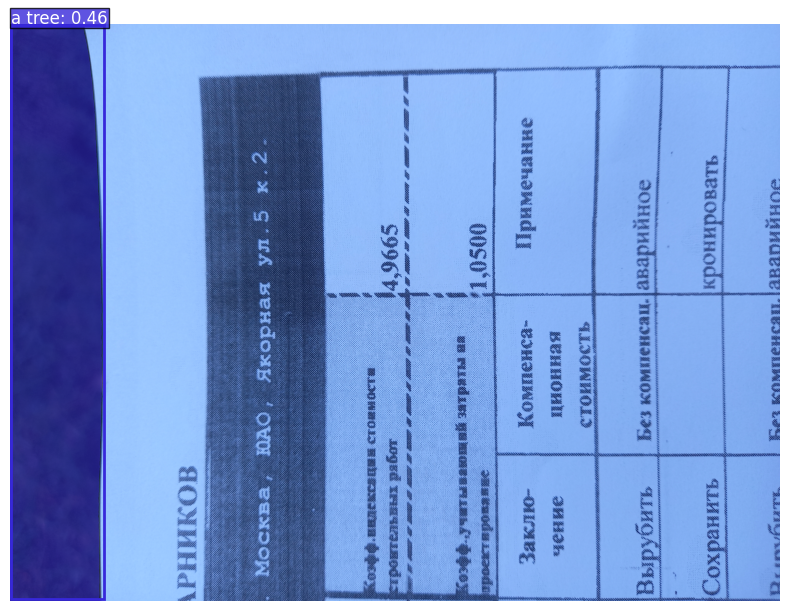

In [249]:
# image_path = Path("data/dataset/") / random.choice(images)
image_path = Path("data/bad/") / random.choice(images)
image = Image.open(image_path).convert("RGB")

hybrid_results = detect_hybrid(
    yolo_model=models['yolo'],
    dino_model=models['dino_model'],
    dino_processor=models['dino_processor'],
    image=image,
    yolo_conf=0.4,
    dino_thresh=0.4,
    iou_thresh=0.5,
    device=DEVICE
)
    
boxes_for_sam = [[int(coord) for coord in box] for box in hybrid_results['boxes']]

masks = segment_objects(
    sam_model=models['sam_model'],
    sam_processor=models['sam_processor'],
    image=image,
    boxes=boxes_for_sam,
    device=DEVICE
)

visualize_segmentation_results(image, hybrid_results, masks)